# Schritt 2 - synthetische Random Graphs für Node Failures

Dieses Notebook ist die Paper-nahe Reihe für synthetische Random Graphs. Es orientiert sich bewusst an den alten Plot-Notebooks `plots_synthetic.ipynb`.

- CSV-Dateien werden in festen Serien geladen.
- `allInOne(...)` berechnet Resilience und durchschnittliche Hops.
- `plotEvalAx2(...)` erstellt die 2x3-Übersicht wie im Paper-Stil.

Der Unterschied zu Schritt 1: Die Algorithmen bleiben gleich, aber die Ausfälle sind Node/Vertex Failures. Ausgefallene Knoten werden intern in alle inzidenten ausgefallenen Kanten übersetzt.


## Technisches Setup

Diese Zelle bereitet nur Pfade, Ausgabeordner und die drei Paper-Graphen vor.


In [1]:
from pathlib import Path

from IPython.display import Image, display


def find_step2_root():
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if candidate.name == "schritt2_knotenausfaelle":
            return candidate
        nested = candidate / "schritt2_knotenausfaelle"
        if nested.exists():
            return nested
    return Path(r"C:\Users\test\ba-gamous-disjoint\schritt2_knotenausfaelle")


STEP2_ROOT = find_step2_root()
SRC_ROOT = STEP2_ROOT / "src"
EVALUATION_ROOT = STEP2_ROOT / "evaluation"
OUTPUT_ROOT = EVALUATION_ROOT / "output"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

PAPER_GRAPHS = [
    {"label": "n25_p015", "title": "Rnd. Graph (n=25, p=0.15)", "nodes": 25, "p": 0.15, "p_label": "0.15"},
    {"label": "n50_p015", "title": "Rnd. Graph (n=50, p=0.15)", "nodes": 50, "p": 0.15, "p_label": "0.15"},
    {"label": "n100_p002", "title": "Rnd. Graph (n=100, p=0.02)", "nodes": 100, "p": 0.02, "p_label": "0.02"},
]

## Auswertungsmethode wie im Paper-Notebook

Die folgende Code-Zelle enthält Hilfsfunktionen für die Auswertung. Sie liest vorhandene CSV-Dateien ein und berechnet daraus Resilience und durchschnittliche Hops.

Die Logik ist bewusst nah an den ursprünglichen Plot-Notebooks gehalten. Für Schritt 2 werden nun Node-Failure-Ergebnisse ausgewertet; die zusätzliche Spalte `nrFailedNodes` kann zur Kontrolle der tatsächlich ausgefallenen Knoten genutzt werden.


In [2]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _mean_or_nan(values):
    return float(np.mean(values)) if len(values) else np.nan


def _filter_arrays_to_success(arr1, arr1_positive, arr2, arr2_positive):
    both_positive = np.logical_and(arr1_positive, arr2_positive)
    return arr1[both_positive], arr2[both_positive]


def allInOne(path, i, rPathsArr, rOneArr, rMultArr, avgHopsPathsArr, avgHopsOneArr, avgHopsMultArr, avgHopsSPArr, printRes=True):
    path = Path(path)
    if not path.exists():
        print(f"Fehlt noch: {path.name}")
        return None

    df = pd.read_csv(path)
    if printRes:
        display(df.head(5))

    hopsRanked = df["hopsRanked"].to_numpy()
    hopsRankedOne = df["hopsRankedOne"].to_numpy()
    hopsPath = df["hopsPath"].to_numpy()
    spLength = df["spLength"].to_numpy()

    hopsRankedPositive = hopsRanked > -1
    hopsRankedOnePositive = hopsRankedOne > -1
    hopsPathPositive = hopsPath > -1
    spLengthPositive = spLength > -1

    total = len(df.index)
    successesRanked = np.count_nonzero(hopsRankedPositive)
    successesRankedOne = np.count_nonzero(hopsRankedOnePositive)
    successesPath = np.count_nonzero(hopsPathPositive)

    avgHopsPath = _mean_or_nan(hopsPath[hopsPathPositive])

    _, hopsRankedFiltered = _filter_arrays_to_success(hopsPath, hopsPathPositive, hopsRanked, hopsRankedPositive)
    avgHopsMult = _mean_or_nan(hopsRankedFiltered)

    _, hopsRankedOneFiltered = _filter_arrays_to_success(hopsPath, hopsPathPositive, hopsRankedOne, hopsRankedOnePositive)
    avgHopsOne = _mean_or_nan(hopsRankedOneFiltered)

    avgSpLength = _mean_or_nan(spLength[spLengthPositive])

    percentPaths = (successesPath / total) * 100
    percentOne = (successesRankedOne / total) * 100
    percentRanked = (successesRanked / total) * 100

    rPathsArr[i] = percentPaths
    rOneArr[i] = percentOne
    rMultArr[i] = percentRanked
    avgHopsPathsArr[i] = avgHopsPath
    avgHopsOneArr[i] = avgHopsOne
    avgHopsMultArr[i] = avgHopsMult
    avgHopsSPArr[i] = avgSpLength

    if printRes:
        print("Resilience Paths: {}%".format(percentPaths))
        print("Resilience One Tree: {}%".format(percentOne))
        print("Resilience Trees: {}%".format(percentRanked))
        print("Avg. failed nodes:", df["nrFailedNodes"].mean() if "nrFailedNodes" in df else "n/a")

    return df


def init_eval_arrays(nrFiles):
    return {
        "rPaths": [np.nan] * nrFiles,
        "rOne": [np.nan] * nrFiles,
        "rMult": [np.nan] * nrFiles,
        "avgHopsPaths": [np.nan] * nrFiles,
        "avgHopsOne": [np.nan] * nrFiles,
        "avgHopsMult": [np.nan] * nrFiles,
        "avgHopsSP": [np.nan] * nrFiles,
    }


def evaluate_series(path_base, files, printRes=False):
    arrays = init_eval_arrays(len(files))
    for i, file_name in enumerate(files):
        allInOne(
            Path(path_base) / file_name,
            i,
            arrays["rPaths"], arrays["rOne"], arrays["rMult"],
            arrays["avgHopsPaths"], arrays["avgHopsOne"], arrays["avgHopsMult"], arrays["avgHopsSP"],
            printRes=printRes,
        )
    return arrays


def plotEval(xVals, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, xlabel="Failure Rate", title="Failure Rate"):
    edp_patch = mpatches.Patch(color="skyblue", label="EDPs")
    onetree_patch = mpatches.Patch(color="darkred", label="One Tree")
    multtrees_patch = mpatches.Patch(color="lightgreen", label="Multiple Trees")
    both_patch = mpatches.Patch(color="violet", label="EDPs + One Tree")

    plt.plot(xVals, rPaths, marker="o", markerfacecolor="blue", markersize=6, color="skyblue", linewidth=4)
    plt.plot(xVals, rOne, marker="o", markerfacecolor="red", markersize=6, color="darkred", linewidth=4)
    plt.plot(xVals, rMult, marker="o", markerfacecolor="green", markersize=6, color="lightgreen", linewidth=4)
    plt.title(f"Resilience - {title}")
    plt.xlabel(xlabel)
    plt.ylabel("Resilience (%)")
    plt.ylim(-5, 105)
    plt.legend(handles=[edp_patch, onetree_patch, multtrees_patch])
    plt.show()

    plt.plot(xVals, avgHopsPaths, marker="o", markerfacecolor="purple", markersize=6, color="violet", linewidth=4)
    plt.plot(xVals, avgHopsMult, marker="o", markerfacecolor="green", markersize=6, color="lightgreen", linewidth=4)
    plt.title(f"Avg. Hops - {title}")
    plt.xlabel(xlabel)
    plt.ylabel("Average Hops")
    plt.legend(handles=[both_patch, multtrees_patch])
    plt.show()


def plotEvalAx2(xVals, ax, rPaths, rOne, rMult, avgHopsPaths, avgHopsOne, avgHopsMult, avgHopsSP, markersize=3, alpha=1):
    linewidth = 2
    ax1, ax2, index = ax

    edp_patch = mpatches.Patch(color="skyblue", label="EDPs")
    onetree_patch = mpatches.Patch(color="darkred", label="One Tree")
    multtrees_patch = mpatches.Patch(color="lightgreen", label="Multiple Trees")
    both_patch = mpatches.Patch(color="violet", label="EDPs + One Tree")

    ax1[index].plot(xVals, rPaths, marker="o", markerfacecolor="blue", markersize=markersize, color="skyblue", linewidth=linewidth, alpha=alpha)
    ax1[index].plot(xVals, rOne, marker="x", markerfacecolor="red", markersize=markersize, color="darkred", linewidth=linewidth, alpha=alpha)
    ax1[index].plot(xVals, rMult, marker="o", markerfacecolor="green", markersize=markersize, color="lightgreen", linewidth=linewidth, alpha=alpha)
    ax1[index].set_ylim(-5, 105)

    if index == 0:
        ax1[index].legend(handles=[edp_patch, onetree_patch, multtrees_patch])

    ax2[index].plot(xVals, avgHopsPaths, marker="o", markerfacecolor="purple", markersize=markersize, color="violet", linewidth=linewidth, alpha=1)
    ax2[index].plot(xVals, avgHopsMult, marker="o", markerfacecolor="green", markersize=markersize, color="lightgreen", linewidth=linewidth, alpha=1)

    if index == 0:
        ax2[index].legend(handles=[both_patch, multtrees_patch])

## CSV-Serien wie im Paper-Notebook

Die Wertebereiche folgen der alten Logik:

- Random Failures: Failure-Faktor in Schritten von `0.8`. Dieser Wert ist ein Skalierungsfaktor für die Knoten-Auswahl, keine direkte Prozentangabe.
- Clustered Failures: Failure Rate `0.3` bis `0.9`.

Für die schnelle Kontrolle verwenden wir zuerst kleinere Pilot-Serien. Die längeren BA-Serien sind unten vorbereitet. Die tatsächliche mittlere Anzahl ausgefallener Knoten wird am Ende des Notebooks nochmal kontrolliert.


In [3]:
def random_values_for_graph(nodes):
    end = {25: 8.8, 50: 16.8, 100: 49.6}[nodes]
    values = []
    x = 0.8
    while x <= end + 1e-9:
        values.append(round(x, 1))
        x = round(x + 0.8, 1)
    return values


def clustered_values():
    return [round(x, 1) for x in np.arange(0.3, 1.0, 0.1)]


def csv_name(graph, value):
    return f"trees-p{graph['p_label']}-n{graph['nodes']}-ff{value}.csv"


def series_files(graph, values):
    return [csv_name(graph, value) for value in values]


PILOT_RANDOM_VALUES = [0.8, 1.6, 2.4, 3.2]
PILOT_CLUSTERED_VALUES = [0.3, 0.5, 0.7, 0.9]
BA_RANDOM_VALUES = {graph["label"]: random_values_for_graph(graph["nodes"]) for graph in PAPER_GRAPHS}
BA_CLUSTERED_VALUES = clustered_values()

series_overview = []
for graph in PAPER_GRAPHS:
    random_values = BA_RANDOM_VALUES[graph["label"]]
    series_overview.append({
        "failure_model": "random",
        "graph": graph["label"],
        "first_value": random_values[0],
        "last_value": random_values[-1],
        "expected_csv_files": len(random_values),
    })
    series_overview.append({
        "failure_model": "clustered",
        "graph": graph["label"],
        "first_value": BA_CLUSTERED_VALUES[0],
        "last_value": BA_CLUSTERED_VALUES[-1],
        "expected_csv_files": len(BA_CLUSTERED_VALUES),
    })

pd.DataFrame(series_overview)

,failure_model,graph,first_value,last_value,expected_csv_files
0,random,n25_p015,0.8,8.8,11
1,clustered,n25_p015,0.3,0.9,7
2,random,n50_p015,0.8,16.8,21
3,clustered,n50_p015,0.3,0.9,7
4,random,n100_p002,0.8,49.6,62
5,clustered,n100_p002,0.3,0.9,7


## CSV-Ordner festlegen

Das Notebook zeigt nur auf vorhandene Ergebnisordner und liest die CSV-Dateien daraus ein. 

Die Generierung passiert ausserhalb des Plot-Notebooks mit `kResilienceTrees.py`.


In [4]:
def result_dir(failure_model, graph, suffix):
    return SRC_ROOT / f"output_node_er_{failure_model}_{graph['label']}_{suffix}"


def check_series_exists(input_dir, files, label):
    input_dir = Path(input_dir)
    missing = [file_name for file_name in files if not (input_dir / file_name).exists()]
    existing_count = len(files) - len(missing)
    if missing:
        print(f"{label}: {existing_count}/{len(files)} CSV-Dateien vorhanden; {len(missing)} fehlen.")
        for file_name in missing[:10]:
            print("-", file_name)
        if len(missing) > 10:
            print("...", len(missing) - 10, "weitere")
    else:
        print(f"{label}: {len(files)}/{len(files)} CSV-Dateien vorhanden.")
    return missing

## Pilot-Kontrolle: n=25, p=0.15

Dieser Abschnitt ist eine schnelle Plausibilitätskontrolle mit wenigen CSV-Dateien. Er gehört nicht zu den finalen BA-Plots, sondern hilft zu pruefen, ob CSV-Import und Auswertung grundsätzlich funktionieren.

Auch hier werden nur vorhandene Pilot-CSV-Dateien eingelesen.


In [5]:
graph_n25 = PAPER_GRAPHS[0]

random_n25_pilot_dir = result_dir("random", graph_n25, "pilot5")
clustered_n25_pilot_dir = result_dir("clustered", graph_n25, "pilot5")

_ = check_series_exists(random_n25_pilot_dir, series_files(graph_n25, PILOT_RANDOM_VALUES), "Pilot random n25_p015")
_ = check_series_exists(clustered_n25_pilot_dir, series_files(graph_n25, PILOT_CLUSTERED_VALUES), "Pilot clustered n25_p015")

Pilot random n25_p015: 4/4 CSV-Dateien vorhanden.
Pilot clustered n25_p015: 4/4 CSV-Dateien vorhanden.


## Pilot-Einzelplots für n=25

Die folgenden zwei Zellen zeigen Kontrollplots für `n=25`. Jede Zelle erzeugt zwei Diagramme: zuerst Resilience, danach durchschnittliche Hops. Die finalen 2x3-BA-Plots kommen weiter unten im Notebook.

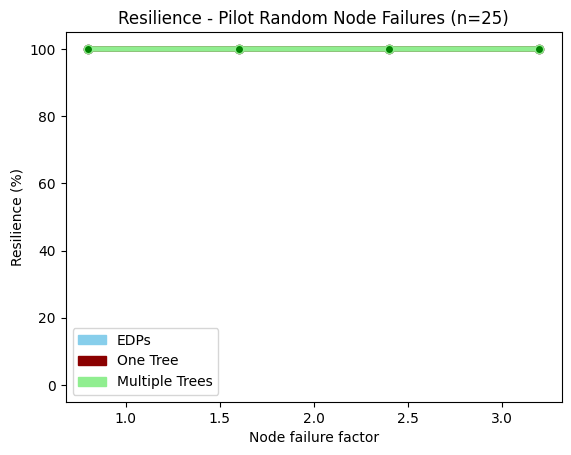

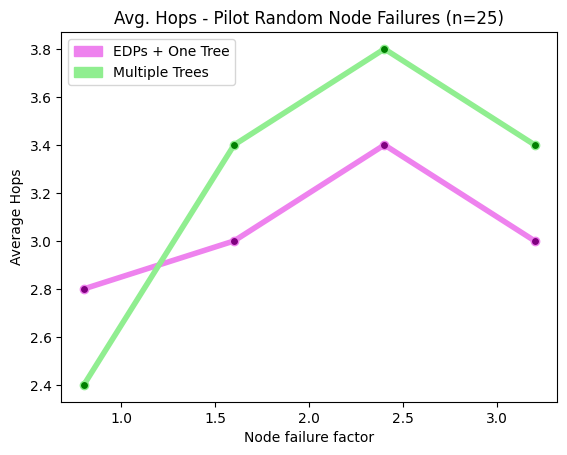

In [6]:
files = series_files(graph_n25, PILOT_RANDOM_VALUES)
arrays = evaluate_series(random_n25_pilot_dir, files, printRes=False)
plotEval(PILOT_RANDOM_VALUES, **arrays, xlabel="Node failure factor", title="Pilot Random Node Failures (n=25)")

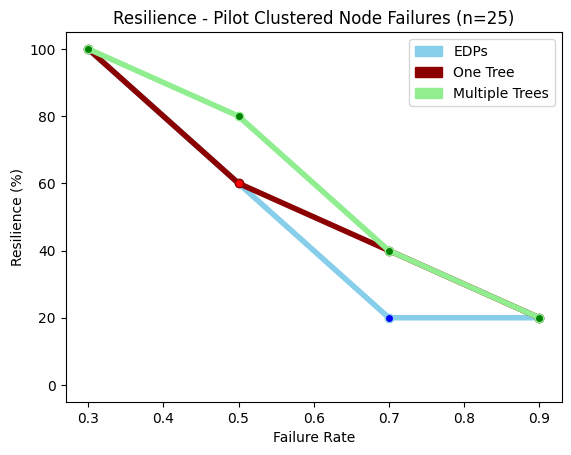

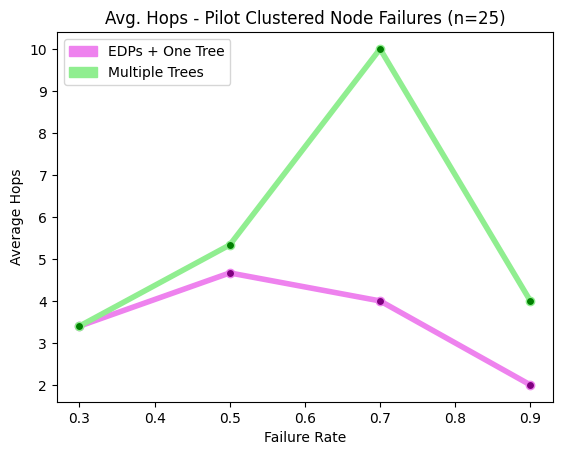

In [7]:
files = series_files(graph_n25, PILOT_CLUSTERED_VALUES)
arrays = evaluate_series(clustered_n25_pilot_dir, files, printRes=False)
plotEval(PILOT_CLUSTERED_VALUES, **arrays, xlabel="Failure Rate", title="Pilot Clustered Node Failures (n=25)")

## Hilfsfunktion für 2x3-Paperplots

Diese Funktion baut denselben Plot-Typ wie `plots_synthetic.ipynb`: oben Resilience, unten durchschnittliche Hops, nebeneinander für `n=25`, `n=50`, `n=100`.

Die Funktion liest vorhandene CSV-Serien, speichert den Plot als PNG und SVG und zeigt anschließend das gespeicherte PNG im Notebook an. Die eigentlichen Ergebnisplots werden in den späteren Zellen erzeugt.


In [8]:
def plot_paper_grid(failure_model, values_by_label, suffix, output_name, xlabel, figure_title):
    fig, (ax1, ax2) = plt.subplots(2, 3, figsize=(10, 5.8))
    fig.suptitle(figure_title, fontsize=16, fontweight="bold", y=0.98)
    plt.subplots_adjust(left=0.1, bottom=0.1, right=1, top=0.84, wspace=0.15, hspace=0.3)

    fontsize1 = 14
    fontsize2 = 20
    fontsize3 = 14

    for index, graph in enumerate(PAPER_GRAPHS):
        values = values_by_label[graph["label"]] if isinstance(values_by_label, dict) else values_by_label
        output_dir = SRC_ROOT / f"output_node_er_{failure_model}_{graph['label']}_{suffix}"
        arrays = evaluate_series(output_dir, series_files(graph, values), printRes=False)

        ax1[index].set_title(graph["title"], fontsize=fontsize1, fontweight="bold")
        ax1[index].set_xlabel(xlabel, labelpad=-1, fontsize=fontsize3)
        ax2[index].set_xlabel(xlabel, labelpad=-1, fontsize=fontsize3)
        if index == 0:
            ax1[index].set_ylabel("Resilience (%)", fontsize=fontsize2)
            ax2[index].set_ylabel("Avg. Hops", fontsize=fontsize2)

        plotEvalAx2(values, (ax1, ax2, index), **arrays, markersize=3, alpha=1)

        if values:
            padding = 0.1 if len(values) == 1 else (max(values) - min(values)) * 0.05
            ax1[index].set_xlim(min(values) - padding, max(values) + padding)
            ax2[index].set_xlim(min(values) - padding, max(values) + padding)

        hop_values = np.array(arrays["avgHopsPaths"] + arrays["avgHopsMult"], dtype=float)
        finite_hops = hop_values[np.isfinite(hop_values)]
        if len(finite_hops) == 0:
            ax2[index].set_ylim(0, 1)
        else:
            ax2[index].set_ylim(0, max(finite_hops) * 1.15)

    output_path = OUTPUT_ROOT / output_name
    fig.savefig(output_path, bbox_inches="tight")
    fig.savefig(output_path.with_suffix(".svg"), bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(output_path)))
    return output_path

## Pilot-CSV-Kontrolle für alle drei Paper-Graphen

Diese Zelle prüft vor dem Pilot-Grid, ob die benötigten Pilot-CSV-Dateien für `n=25`, `n=50` und `n=100` vorhanden sind.


In [9]:
for graph in PAPER_GRAPHS:
    check_series_exists(result_dir("random", graph, "pilot5"), series_files(graph, PILOT_RANDOM_VALUES), f"Pilot random {graph['label']}")
    check_series_exists(result_dir("clustered", graph, "pilot5"), series_files(graph, PILOT_CLUSTERED_VALUES), f"Pilot clustered {graph['label']}")

Pilot random n25_p015: 4/4 CSV-Dateien vorhanden.
Pilot clustered n25_p015: 4/4 CSV-Dateien vorhanden.
Pilot random n50_p015: 4/4 CSV-Dateien vorhanden.
Pilot clustered n50_p015: 4/4 CSV-Dateien vorhanden.
Pilot random n100_p002: 4/4 CSV-Dateien vorhanden.
Pilot clustered n100_p002: 4/4 CSV-Dateien vorhanden.


## Optionaler Pilot-Grid

Diese zwei Zellen erzeugen 2x3-Kontrollplots aus den kleinen Pilot-CSV-Dateien. Sie sind hilfreich, um die Darstellung und die Importlogik zu pruefen.

Für die BA-Auswertung sind die 1000-Run-Plots weiter unten entscheidend; der Pilot-Grid ist nur eine "Vorabkontrolle".


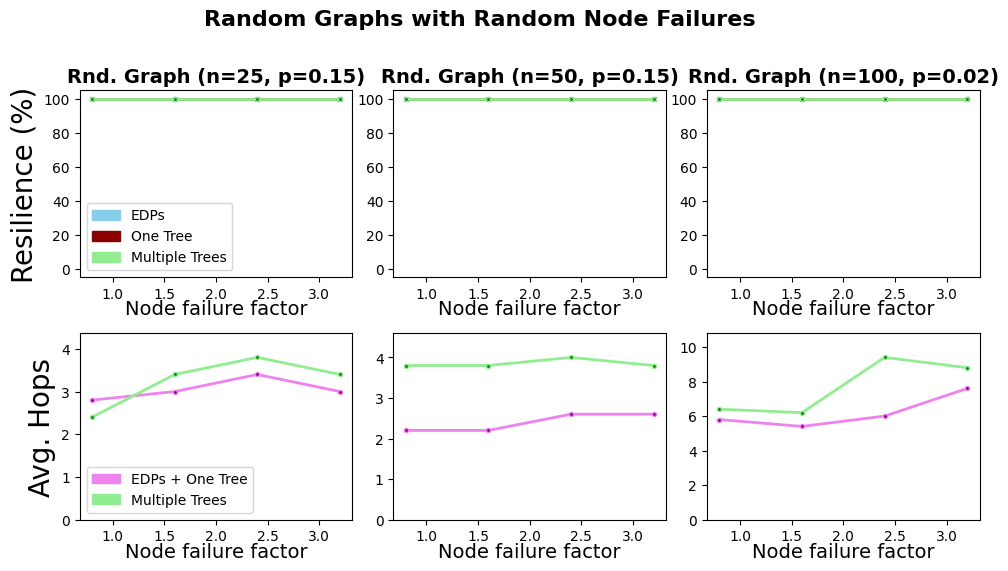

In [10]:
pilot_random_values = {graph["label"]: PILOT_RANDOM_VALUES for graph in PAPER_GRAPHS}
random_pilot_grid_path = plot_paper_grid(
    failure_model="random",
    values_by_label=pilot_random_values,
    suffix="pilot5",
    output_name="notebook_node_er_random_paper_pilot5.png",
    xlabel="Node failure factor",
    figure_title="Random Graphs with Random Node Failures",
)

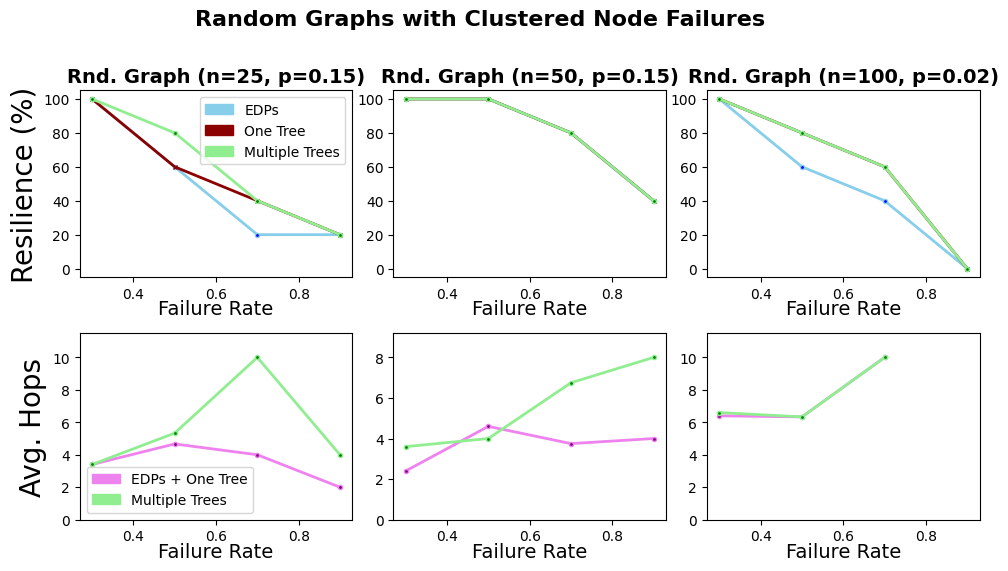

In [11]:
pilot_clustered_values = {graph["label"]: PILOT_CLUSTERED_VALUES for graph in PAPER_GRAPHS}
clustered_pilot_grid_path = plot_paper_grid(
    failure_model="clustered",
    values_by_label=pilot_clustered_values,
    suffix="pilot5",
    output_name="notebook_node_er_clustered_paper_pilot5.png",
    xlabel="Failure Rate",
    figure_title="Random Graphs with Clustered Node Failures",
)

## BA-Plots mit 1000 Runs

Diese Zelle erzeugt die finalen 2x3-Plots aus den vorhandenen `runs1000`-CSV-Dateien. Sie prüft zuerst, ob alle erwarteten CSV-Dateien vorhanden sind, importiert die CSV-Dateien und erstellt danach je einen Plot für Random Node Failures und Clustered Node Failures.

Für die BA sind vor allem diese beiden gespeicherten Dateien relevant:

- `notebook_node_er_random_paper_runs1000.png`
- `notebook_node_er_clustered_paper_runs1000.png`


1000 Runs random n25_p015: 11/11 CSV-Dateien vorhanden.
1000 Runs clustered n25_p015: 7/7 CSV-Dateien vorhanden.
1000 Runs random n50_p015: 21/21 CSV-Dateien vorhanden.
1000 Runs clustered n50_p015: 7/7 CSV-Dateien vorhanden.
1000 Runs random n100_p002: 62/62 CSV-Dateien vorhanden.
1000 Runs clustered n100_p002: 7/7 CSV-Dateien vorhanden.


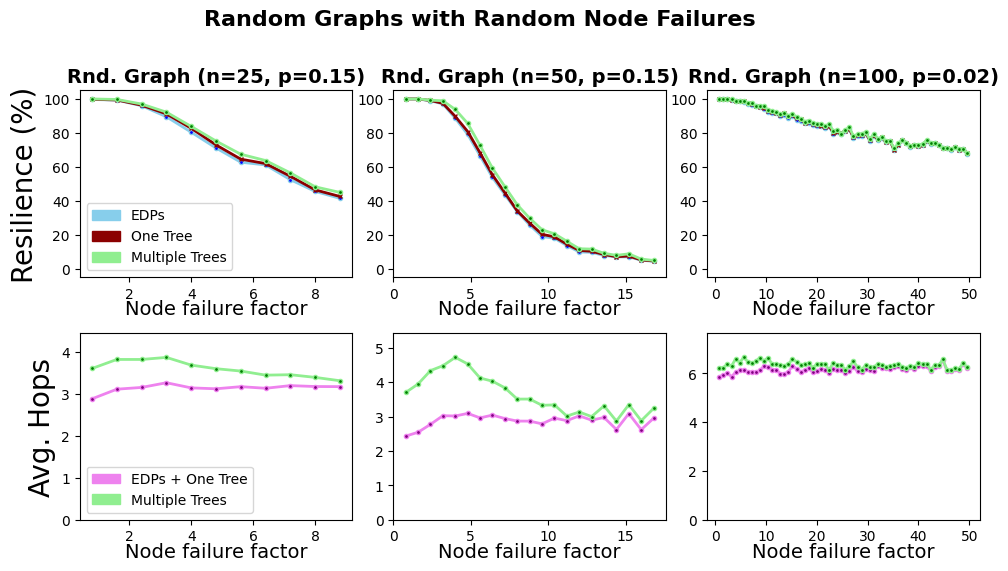

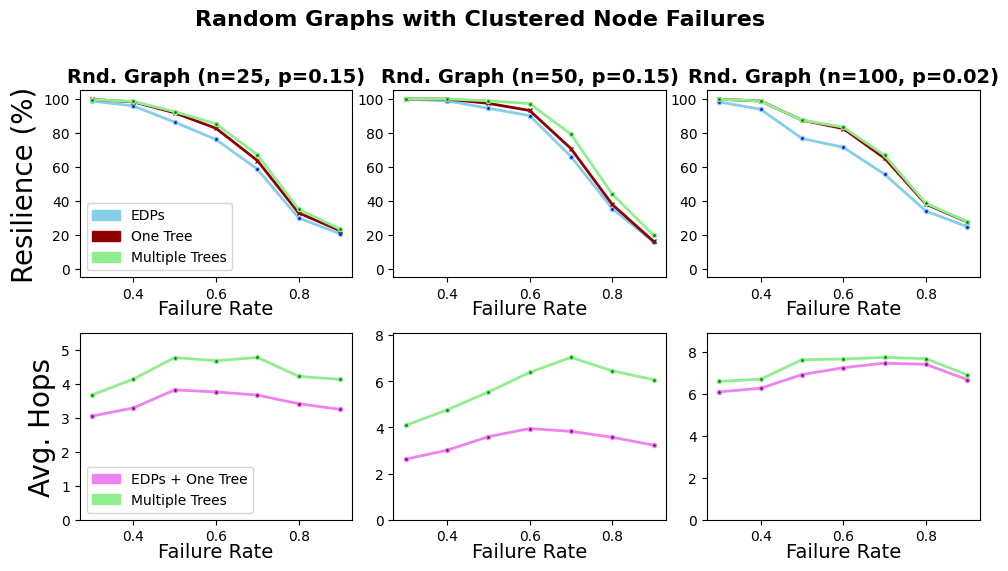

In [12]:
RUNS1000_SUFFIX = "runs1000"

for graph in PAPER_GRAPHS:
    check_series_exists(result_dir("random", graph, RUNS1000_SUFFIX), series_files(graph, BA_RANDOM_VALUES[graph["label"]]), f"1000 Runs random {graph['label']}")
    check_series_exists(result_dir("clustered", graph, RUNS1000_SUFFIX), series_files(graph, BA_CLUSTERED_VALUES), f"1000 Runs clustered {graph['label']}")

random_runs1000_grid_path = plot_paper_grid(
    "random",
    BA_RANDOM_VALUES,
    RUNS1000_SUFFIX,
    "notebook_node_er_random_paper_runs1000.png",
    "Node failure factor",
    "Random Graphs with Random Node Failures",
)

clustered_runs1000_grid_path = plot_paper_grid(
    "clustered",
    BA_CLUSTERED_VALUES,
    RUNS1000_SUFFIX,
    "notebook_node_er_clustered_paper_runs1000.png",
    "Failure Rate",
    "Random Graphs with Clustered Node Failures",
)

## CSV-Inhaltskontrolle für 1000-Run-Node-Failures

Diese Zelle kontrolliert alle 1000-Run-CSV-Ordner: Random und Clustered Node Failures für `n=25`, `n=50` und `n=100`. Sie prüft die Dateianzahl, Zeilenzahl, Parameterwerte und ob `nrFailedNodes` vorhanden ist.

Die Tabelle ist als Nachweis gedacht: `csv_files` zeigt die Anzahl vorhandener CSV-Dateien pro Reihe, `rows_per_csv` die Wiederholungen pro Datei, `all_complete` ob alle Dateien 1000 Zeilen haben. `avg_failed_nodes_first` und `avg_failed_nodes_last` zeigen die mittlere Anzahl ausgefallener Knoten beim ersten und letzten x-Achsenwert.


In [13]:
def check_csv_contents(failure_model, graph, values, suffix):
    input_dir = result_dir(failure_model, graph, suffix)
    rows = []
    problems = []
    required_columns = {
        "rep", "nrNodes", "nrEdges", "edgeProb", "nrPaths", "failureModel",
        "nrFailedNodes", "hopsPath", "hopsRankedOne", "hopsRanked",
    }

    for value, file_name in zip(values, series_files(graph, values)):
        csv_path = input_dir / file_name
        if not csv_path.exists():
            problems.append(f"missing {csv_path.name}")
            continue

        df = pd.read_csv(csv_path)
        missing_columns = sorted(required_columns - set(df.columns))
        if len(df.index) != 1000:
            problems.append(f"{csv_path.name}: rows={len(df.index)}")
        if missing_columns:
            problems.append(f"{csv_path.name}: missing columns={missing_columns}")
        if set(df["nrNodes"].dropna().unique()) != {graph["nodes"]}:
            problems.append(f"{csv_path.name}: wrong nrNodes")
        if not all(abs(float(x) - graph["p"]) < 1e-9 for x in df["edgeProb"].dropna().unique()):
            problems.append(f"{csv_path.name}: wrong edgeProb")
        if set(df["failureModel"].dropna().unique()) != {failure_model}:
            problems.append(f"{csv_path.name}: wrong failureModel")

        rows.append({
            "failure_model": failure_model,
            "graph": graph["label"],
            "failure_value": value,
            "rows": len(df.index),
            "avg_failed_nodes": df["nrFailedNodes"].mean(),
            "EDPs_resilience": (df["hopsPath"] > -1).mean(),
            "OneTree_resilience": (df["hopsRankedOne"] > -1).mean(),
            "MultipleTrees_resilience": (df["hopsRanked"] > -1).mean(),
        })

    return pd.DataFrame(rows), problems


all_summaries = []
all_problems = []

for graph in PAPER_GRAPHS:
    summary, problems = check_csv_contents("random", graph, BA_RANDOM_VALUES[graph["label"]], "runs1000")
    all_summaries.append(summary)
    all_problems.extend(problems)

    summary, problems = check_csv_contents("clustered", graph, BA_CLUSTERED_VALUES, "runs1000")
    all_summaries.append(summary)
    all_problems.extend(problems)

csv_content_summary = pd.concat(all_summaries, ignore_index=True)
readable_check = csv_content_summary.groupby(["failure_model", "graph"]).agg(
    csv_files=("failure_value", "count"),
    rows_per_csv=("rows", "first"),
    all_complete=("rows", lambda rows: bool((rows == 1000).all())),
    avg_failed_nodes_first=("avg_failed_nodes", "first"),
    avg_failed_nodes_last=("avg_failed_nodes", "last"),
).reset_index()

failure_model_order = {"random": 0, "clustered": 1}
graph_order = {"n25_p015": 0, "n50_p015": 1, "n100_p002": 2}
readable_check = readable_check.assign(
    _failure_model_order=readable_check["failure_model"].map(failure_model_order),
    _graph_order=readable_check["graph"].map(graph_order),
).sort_values(["_failure_model_order", "_graph_order"]).drop(columns=["_failure_model_order", "_graph_order"]).reset_index(drop=True)

display(readable_check)

if all_problems:
    print("Probleme gefunden:")
    for problem in all_problems[:30]:
        print("-", problem)
else:
    print("Alle 1000-Run-CSV-Dateien sind inhaltlich plausibel.")

,failure_model,graph,csv_files,rows_per_csv,all_complete,avg_failed_nodes_first,avg_failed_nodes_last
0,random,n25_p015,11,1000,True,1.365,12.216
1,random,n50_p015,21,1000,True,3.833,45.780
2,random,n100_p002,62,1000,True,0.384,20.822
3,clustered,n25_p015,7,1000,True,0.516,10.034
4,clustered,n50_p015,7,1000,True,1.728,29.184
5,clustered,n100_p002,7,1000,True,0.169,5.856


Alle 1000-Run-CSV-Dateien sind inhaltlich plausibel.
